# Backtests de la pérdida esperada: Acerbi-Szekely con valores críticos simulados, Du-Escanciano y McNeil-Frey

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 03 de este tema (los backtests de excepciones)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- explicar por qué un conteo de excepciones del VaR no puede contrastar una pérdida esperada, y qué miden en cambio los estadísticos $Z_1$ y $Z_2$ de Acerbi-Szekely;
- calcular $Z_2$ a mano desde pérdidas, VaR y ES, y obtener el valor versionado;
- decir qué le pide el motor al llamador para obtener un valor crítico, qué nula suministra Contraste, y por qué los valores críticos difieren de un modelo a otro;
- comparar el valor crítico simulado de cada modelo con el punto de referencia publicado de $-0,70$ y $-1,8$, y decir qué es y qué no es esa referencia;
- ejecutar las pruebas de Du-Escanciano y de McNeil-Frey sobre un modelo cuya distribución predictiva se conoce, y leer qué agrega cada una a $Z_2$.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Los valores de luz del motor, con las palabras que imprime este cuaderno
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Las pruebas de ES necesitan la pérdida realizada de cada día, así que el cuaderno trabaja con las dos ventanas del caso C11 que la versionan: `fx-2008` (el euro frente al dólar, 251 días) y `rates-2022` (una posición en el bono del Tesoro a 10 años, 249 días), ambas construidas sobre series `mirror-allowed`. Para cada uno de los 17 modelos y cada nivel de cola los archivos guardan el VaR y la ES (pérdidas positivas) y, para los modelos que pronostican una ES, el resultado de Acerbi-Szekely versionado con el histograma de su nula simulada. `equity-2007-09` se lee solo por sus filas versionadas: sus retornos son solo derivados.

Tres escalones no pronostican una ES (`cf-rolling`, `caviar-sav`, `caviar-as`), así que las pruebas de ES no se les aplican y el motor devolvería `not_evaluated`; el cuaderno los omite. La celda siguiente carga los archivos y lista qué modelos tienen una ES.

In [2]:
# Cargar las dos ventanas que versionan las pérdidas realizadas, más la crisis accionaria por sus filas versionadas, y listar los modelos con ES
ROOT = Path("../../..").resolve()
docs = {w: json.loads((ROOT / "data" / "derived" / "C11" / f"{w}.json").read_text(encoding="utf-8")) for w in ("fx-2008", "rates-2022", "equity-2007-09")}
print("filas versionadas calculadas por riskvalidation", docs["fx-2008"]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

fx = docs["fx-2008"]["outputs"]
models = {m["model_id"]: m for m in fx["models"]}
with_es = [mid for mid, m in models.items() if all(lv["es_status"] == "forecast" for lv in m["by_level"])]
print("modelos con ES:", len(with_es), "de", len(models))
print("sin ES:", [mid for mid in models if mid not in with_es])
loss = np.array(fx["grid"]["realised_loss"]["loss"])
print("fx-2008: pérdidas realizadas", loss.size, "| niveles de cola", [lv["alpha"] for lv in fx["levels"]])

filas versionadas calculadas por riskvalidation 1.0.1 | instalado 1.0.1
modelos con ES: 14 de 17
sin ES: ['cf-rolling', 'caviar-sav', 'caviar-as']
fx-2008: pérdidas realizadas 251 | niveles de cola [0.01, 0.025]


## Método

### Paso 1: por qué la ES necesita su propia prueba, y los estadísticos $Z_1$ y $Z_2$

La pérdida esperada es una afirmación sobre **cuán grandes** son las pérdidas cuando se supera el VaR. El número de excepciones no dice nada de su tamaño: dos modelos con el mismo VaR y el mismo conteo pueden tener una ES muy distinta, y solo uno de ellos es correcto. Acerbi y Szekely (2014) contrastan la ES con estadísticos construidos desde el tamaño de la pérdida en los días de excepción relativo a la ES pronosticada. Con $X_t = -\text{pérdida}_t$, $I_t = \mathbb 1\{\text{pérdida}_t > \text{VaR}_t\}$ y $N_T = \sum_t I_t$:

$$Z_1 = \frac{1}{N_T}\sum_{t=1}^{T}\frac{X_t\,I_t}{\mathrm{ES}_t} + 1, \qquad Z_2 = \sum_{t=1}^{T}\frac{X_t\,I_t}{T\,\alpha\,\mathrm{ES}_t} + 1$$

$Z_1$ promedia, solo sobre los días de excepción, la razón entre la pérdida realizada y la ES pronosticada: vale 0 cuando las pérdidas son, en promedio, tan grandes como dice la ES, y es negativo cuando son mayores. $Z_2$ reemplaza $N_T$ por el conteo esperado $T\alpha$, de modo que penaliza también un **número equivocado** de excepciones. Ambos tienen esperanza 0 bajo la nula de que los pronósticos son correctos, y ambos son negativos cuando se subestima el riesgo. La celda calcula ambos a mano para cada modelo con ES, en ambos niveles, y pone $Z_2$ junto al valor versionado.

In [3]:
# Z1 y Z2 a mano desde las pérdidas, el VaR y la ES de cada modelo con ES, y Z2 frente al valor versionado
committed_bt = {(x["model_id"], x["alpha"]): x for x in fx["es_backtests"]}
peor = 0.0
print(f"{'modelo':11s} {'alfa':>6s} {'excep.':>7s} {'Z1':>9s} {'Z2':>9s} {'Z2 versionado':>13s}")
for mid in with_es:
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        exceed = loss > var
        z1 = -(loss[exceed] / es[exceed]).mean() + 1.0 if exceed.any() else float("nan")
        z2 = -(loss[exceed] / es[exceed]).sum() / (loss.size * alpha) + 1.0
        committed = committed_bt[(mid, alpha)]["realised"]
        peor = max(peor, abs(z2 - committed))
        if mid in ("hs-250", "ewma", "garch-t", "dn-rolling", "evt-mf", "gas-fz-2"):
            print(f"{mid:11s} {alpha:6.3f} {int(exceed.sum()):7d} {z1:9.4f} {z2:9.4f} {committed:13.4f}")
print(f"mayor diferencia entre Z2 a mano y el valor versionado, los {len(with_es)} modelos y ambos niveles: {peor:.2e}")

modelo        alfa  excep.        Z1        Z2 Z2 versionado
hs-250       0.010      10   -0.0691   -3.2592       -3.2592
hs-250       0.025      13   -0.1350   -1.3513       -1.3513
dn-rolling   0.010      23   -0.2444  -10.4033      -10.4033
dn-rolling   0.025      35   -0.2394   -5.9131       -5.9131
ewma         0.010       3   -0.1242   -0.3437       -0.3437
ewma         0.025       8   -0.0323   -0.3160       -0.3160
garch-t      0.010       3   -0.0402   -0.2433       -0.2433
garch-t      0.025       7   -0.0117   -0.1286       -0.1286
evt-mf       0.010       3   -0.0644   -0.2722       -0.2722
evt-mf       0.025       7   -0.0072   -0.1235       -0.1235
gas-fz-2     0.010      19   -0.3434   -9.1688       -9.1688
gas-fz-2     0.025      21   -0.0171   -2.4038       -2.4038
mayor diferencia entre Z2 a mano y el valor versionado, los 14 modelos y ambos niveles: 3.85e-08


### Paso 2: un valor crítico necesita una nula, y el motor se la pide a quien llama

Un estadístico solo sirve frente a su distribución bajo la nula. Para $Z_2$ no existe un valor crítico universal: depende de la distribución predictiva del modelo. Por eso el motor le pide al llamador `simulate_null(rng)`, una función que devuelve una trayectoria de pérdidas simulada desde las distribuciones predictivas del propio modelo, y calcula el valor p como la fracción de cola izquierda de los estadísticos simulados, $p = (1 + \#\{Z^{sim} \le Z\})/(n_{sim}+1)$. Un modelo histórico, CAViaR o GAS no tiene una distribución predictiva de la que simular, así que Contraste usa **una nula consistente con la cola para todos los escalones** (documentada en `data-pipeline/pipeline/cases/c11/documents.py`): cada día la pérdida supera al VaR con probabilidad $\alpha$, con un exceso exponencial de media $\mathrm{ES}_t - \mathrm{VaR}_t$, y en otro caso queda por debajo. Bajo esta nula $E[\text{pérdida}\,I_t] = \alpha\,\mathrm{ES}_t$, de modo que $E[Z_2] = 0$ por construcción: las pérdidas simuladas reproducen el VaR y la ES del propio modelo, y la prueba solo pregunta si las pérdidas **realizadas** son compatibles con ellos. La forma del exceso es un supuesto declarado (la Pareto generalizada con forma 0); una cola real más pesada vuelve demasiado estrechos los valores críticos.

La celda escribe esa nula como una función corta, la pasa a `acerbi_szekely` con los sorteos (10.000) y la semilla (42) versionados, y compara el valor p y los valores críticos del motor con las filas versionadas. La función es la entrada que pide la API del motor, escrita según la regla documentada del pipeline; la prueba es la del motor.

In [4]:
# La nula consistente con la cola como función del VaR y la ES de un modelo, y luego la prueba Z2 del motor frente a las filas versionadas
from riskvalidation.validation.market import acerbi_szekely


def tail_consistent_null(var, es, alpha):
    """simulate_null para acerbi_szekely: una excepción con probabilidad alfa, con un exceso exponencial de media ES - VaR."""
    excess = es - var

    def simulate(rng):
        hit = rng.random(var.size) < alpha
        return np.where(hit, var + rng.exponential(1.0, var.size) * excess, 0.0)

    return simulate


print(f"{'modelo':11s} {'alfa':>6s} {'Z2':>9s} {'p (motor)':>11s} {'p (versionado)':>14s} {'crít. 5% (motor / versionado)':>30s}")
for mid in ("hs-250", "ewma", "garch-t", "dn-rolling"):
    for level in models[mid]["by_level"]:
        alpha = level["alpha"]
        var, es = np.array(level["var"]), np.array(level["es"])
        result = acerbi_szekely(loss, var, es, alpha, tail_consistent_null(var, es, alpha), model_id=mid, statistic="Z2", n_sim=10000, seed=42)
        row = committed_bt[(mid, alpha)]
        print(f"{mid:11s} {alpha:6.3f} {result.statistic:9.4f} {result.p_value:11.6f} {row['p_value']:14.6f} "
              f"{result.extras['critical_5pct']:14.4f} / {row['critical_5pct']:.4f}")

modelo        alfa        Z2   p (motor) p (versionado)  crít. 5% (motor / versionado)
hs-250       0.010   -3.2592    0.000200       0.000200        -1.0906 / -1.0906
hs-250       0.025   -1.3513    0.001900       0.001900        -0.6950 / -0.6950
ewma         0.010   -0.3437    0.255774       0.255774        -1.1035 / -1.1035
ewma         0.025   -0.3160    0.205379       0.205379        -0.6939 / -0.6939
garch-t      0.010   -0.2433    0.308069       0.308069        -1.1336 / -1.1336
garch-t      0.025   -0.1286    0.351165       0.351165        -0.7060 / -0.7060
dn-rolling   0.010  -10.4033    0.000100       0.000100        -1.1046 / -1.1046
dn-rolling   0.025   -5.9131    0.000100       0.000100        -0.6932 / -0.6932


### Paso 3: el valor crítico pertenece al modelo, y los umbrales publicados son un punto de referencia

La sugerencia publicada para $Z_2$ es una zona amarilla bajo $-0,70$ y una zona roja bajo $-1,8$, para $T = 250$ días con $\alpha = 2,5$ por ciento (Acerbi y Szekely; verificada aquí solo mediante la fuente secundaria de Moldenhauer y Pitera, 2017, sección 6). El motor las guarda en `extras["reference"]` y dice que son un punto de referencia publicado, no un umbral. Las filas versionadas muestran por qué: los valores críticos al 5 por ciento y al 0,01 por ciento dependen de la trayectoria de VaR y ES del modelo, porque el exceso simulado escala con $\mathrm{ES}_t - \mathrm{VaR}_t$ y el estadístico divide por $\mathrm{ES}_t$. La celda lista, para los modelos con ES en `fx-2008`, el rango de los valores críticos versionados en cada nivel frente a la referencia, y luego la tabla al 2,5 por ciento. La luz compara el valor p con 5 por ciento (ámbar) y 0,01 por ciento (rojo), los valores por defecto del motor.

In [5]:
# Valores críticos versionados por modelo al 2,5% en fx-2008 frente al punto de referencia publicado, y la luz de cada modelo
reference = {"yellow": -0.70, "red": -1.8}
for alpha in (0.01, 0.025):
    level_rows = [committed_bt[(mid, alpha)] for mid in with_es]
    crit5 = np.array([r["critical_5pct"] for r in level_rows])
    crit001 = np.array([r["critical_0_01pct"] for r in level_rows])
    print(f"alfa {alpha}: valor crítico de 5% de {crit5.min():.3f} a {crit5.max():.3f} | valor crítico de 0.01% de {crit001.min():.3f} a {crit001.max():.3f} "
          f"| en {len(level_rows)} modelos")
print(f"referencia publicada (T = 250, alfa = 0.025): amarillo {reference['yellow']}, rojo {reference['red']}")
rows = [committed_bt[(mid, 0.025)] for mid in with_es]
light_of = {t["model_id"]: t["light"] for t in docs["fx-2008"]["tests"] if t["test_id"] == "market.acerbi_szekely" and t["segment"] == "alpha=0.025"}
print(f"{'modelo':11s} {'Z2':>9s} {'crít. 5%':>9s} {'crít. 0.01%':>11s} {'p':>9s}  luz")
for r in rows:
    print(f"{r['model_id']:11s} {r['realised']:9.3f} {r['critical_5pct']:9.3f} {r['critical_0_01pct']:11.3f} {r['p_value']:9.5f}  {LIGHT[light_of[r['model_id']]]}")

alfa 0.01: valor crítico de 5% de -1.211 a -1.056 | valor crítico de 0.01% de -3.587 a -2.854 | en 14 modelos
alfa 0.025: valor crítico de 5% de -0.723 a -0.687 | valor crítico de 0.01% de -1.762 a -1.559 | en 14 modelos
referencia publicada (T = 250, alfa = 0.025): amarillo -0.7, rojo -1.8
modelo             Z2  crít. 5% crít. 0.01%         p  luz
hs-250         -1.351    -0.695      -1.609   0.00190  ámbar
hs-500         -3.462    -0.709      -1.649   0.00010  rojo
awhs           -0.750    -0.687      -1.559   0.03800  ámbar
dn-rolling     -5.913    -0.693      -1.581   0.00010  rojo
ewma           -0.316    -0.694      -1.582   0.20538  verde
garch-t        -0.129    -0.706      -1.606   0.35116  verde
gjr-t          -0.269    -0.706      -1.616   0.24218  verde
egarch-t       -0.310    -0.706      -1.619   0.21258  verde
fhs            -0.130    -0.694      -1.584   0.34707  verde
evt-mf         -0.124    -0.699      -1.589   0.35376  verde
caviar-es      -0.381    -0.688      -1.5

La figura dibuja la nula simulada versionada de dos modelos al 2,5 por ciento en `fx-2008`, el pronóstico `ewma`, que pasa, y el `hs-250`, que no, cada uno con su $Z_2$ realizado, su valor crítico de 5 por ciento y la referencia publicada de $-0,70$. La nula está centrada en 0 como debe; el lugar donde cae el estadístico realizado en ella es el valor p.

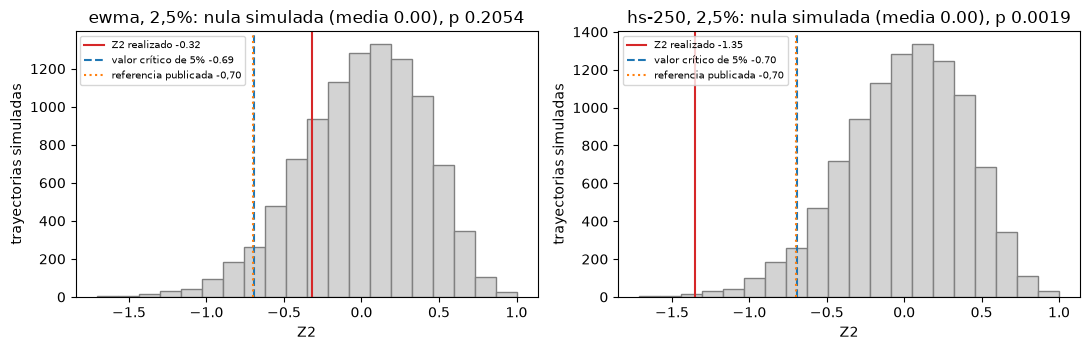

In [6]:
# Dibujar la nula simulada versionada de dos modelos (histograma), el Z2 realizado, el valor crítico de 5% y la referencia publicada
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, mid in zip(axes, ("ewma", "hs-250")):
    row = committed_bt[(mid, 0.025)]
    edges, counts = np.array(row["histogram"]["edges"]), np.array(row["histogram"]["counts"])
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color="lightgrey", edgecolor="grey")
    ax.axvline(row["realised"], color="tab:red", label=f"Z2 realizado {row['realised']:.2f}")
    ax.axvline(row["critical_5pct"], color="tab:blue", linestyle="--", label=f"valor crítico de 5% {row['critical_5pct']:.2f}")
    ax.axvline(reference["yellow"], color="tab:orange", linestyle=":", label="referencia publicada -0,70")
    centre = float((counts * (edges[:-1] + edges[1:]) / 2).sum() / counts.sum())
    ax.set_title(f"{mid}, 2,5%: nula simulada (media {centre:.2f}), p {row['p_value']:.4f}")
    ax.set_xlabel("Z2")
    ax.set_ylabel("trayectorias simuladas")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

### Paso 4: Du-Escanciano, una prueba construida sobre toda la cola

$Z_2$ mira solo los días de excepción. Du y Escanciano (2017) usan la **transformada integral de probabilidad** (PIT) $u_t = F_t(y_t)$, la posición del retorno realizado en la distribución predictiva del modelo, que es uniforme si la distribución es correcta. El proceso de violación acumulada $H_t(\alpha) = \frac{1}{\alpha}(\alpha - u_t)\,\mathbb 1\{u_t \le \alpha\}$ mide cuán adentro de la cola de nivel $\alpha$ cayó la observación: es 0 fuera de la cola y crece hasta 1 en el extremo. Bajo pronósticos correctos $E[H_t] = \alpha/2$ y $\mathrm{Var}(H_t) = \alpha(1/3 - \alpha/4)$, lo que da

$$U_{ES} = \frac{\sqrt{T}\,(\bar H - \alpha/2)}{\sqrt{\alpha(1/3-\alpha/4)}} \xrightarrow{d} N(0,1), \qquad C_{ES}(m) = T\sum_{j=1}^{m}\hat\rho_j^{\,2} \xrightarrow{d} \chi^2_m$$

donde $\hat\rho_j$ son las autocorrelaciones de $H_t - \alpha/2$: el primer estadístico contrasta el nivel de la cola, el segundo si las violaciones de la cola vienen en secuencias. Ambos necesitan una distribución predictiva, así que el cuaderno usa dos modelos cuya distribución es una normal que los pronósticos versionados determinan. `ewma` tiene media cero y una volatilidad que fija el VaR versionado (paso 4 del cuaderno 02). Para `dn-rolling` la media $\mu$ y la volatilidad $\sigma$ son las dos incógnitas de las dos fórmulas delta-normales $v = \mu + z\sigma$ y $e = \mu - \sigma\varphi(z)/\alpha$, que la celda invierte día a día. Las pruebas asintóticas simples ignoran la incertidumbre de los parámetros estimados, como dicen las notas del motor. La batería C11 versionada no corre estas pruebas, así que no hay filas versionadas con qué comparar.

In [7]:
# La normal predictiva de ewma y dn-rolling desde el VaR y la ES versionados, las PIT y las pruebas de Du-Escanciano
from riskvalidation.validation.market import du_escanciano_conditional, du_escanciano_unconditional

returns = -loss


def predictive_normal(model_id, alpha):
    """mu y sigma de la normal del día en la convención de retornos, desde el VaR y la ES versionados (pérdidas)."""
    level = [lv for lv in models[model_id]["by_level"] if lv["alpha"] == alpha][0]
    var, es = np.array(level["var"]), np.array(level["es"])
    z = stats.norm.ppf(alpha)
    if model_id == "ewma":                                   # media cero: el VaR solo fija sigma
        sigma = var / -z
        return np.zeros_like(sigma), sigma, var, es
    sigma = (es - var) / (stats.norm.pdf(z) / alpha + z)     # dos incógnitas, dos ecuaciones
    return -var - z * sigma, sigma, var, es


pits = {}
for mid in ("ewma", "dn-rolling"):
    for alpha in (0.01, 0.025):
        mu, sigma, var, es = predictive_normal(mid, alpha)
        pit = stats.norm.cdf((returns - mu) / sigma)
        h = np.where(pit <= alpha, (alpha - pit) / alpha, 0.0)
        unconditional = du_escanciano_unconditional(pit, alpha, model_id=mid)
        conditional = du_escanciano_conditional(pit, alpha, lags=5, model_id=mid)
        pits[(mid, alpha)] = pit
        print(f"{mid:10s} alfa {alpha:5.3f} | H medio {h.mean():.4f} frente a alfa/2 {alpha / 2:.4f} | U_ES {unconditional.statistic:7.3f} p {unconditional.p_value:.4f} "
              f"{LIGHT[unconditional.light.value]:6s} | C_ES(5) {conditional.statistic:7.3f} p {conditional.p_value:.4f} {LIGHT[conditional.light.value]}")

ewma       alfa 0.010 | H medio 0.0091 frente a alfa/2 0.0050 | U_ES   1.131 p 0.1291 verde  | C_ES(5)  12.670 p 0.0267 rojo
ewma       alfa 0.025 | H medio 0.0150 frente a alfa/2 0.0125 | U_ES   0.434 p 0.3323 verde  | C_ES(5)  16.247 p 0.0062 rojo
dn-rolling alfa 0.010 | H medio 0.0736 frente a alfa/2 0.0050 | U_ES  18.909 p 0.0000 rojo   | C_ES(5)   8.552 p 0.1283 verde
dn-rolling alfa 0.025 | H medio 0.0969 frente a alfa/2 0.0125 | U_ES  14.780 p 0.0000 rojo   | C_ES(5)  10.452 p 0.0634 ámbar


### Paso 5: McNeil-Frey, el tamaño del exceso sobre la ES

McNeil y Frey (2000) miran los días de excepción y preguntan si el exceso sobre la ES, escalado por la volatilidad del día, es cero en promedio: $r_t = (L_t - \mathrm{ES}_t)/\sigma_t$ debería ser independiente con media cero cuando la ES es correcta, y una media positiva significa que la ES es demasiado baja. La función `mcneil_frey_residual_test` del motor recibe las pérdidas, el VaR, la ES y $\sigma_t$, y contrasta una media cero con un bootstrap unilateral: los residuos centrados en su media se remuestrean y $p = (1 + \#\{\bar r^* \ge \bar r\})/(n_{boot}+1)$. Es una prueba del **tamaño** de las pérdidas más allá del VaR que requiere pocos supuestos, y necesita al menos dos excepciones. La ejecutamos con el $\sigma_t$ del paso 4.

In [8]:
# La prueba de residuos de McNeil-Frey sobre los días de excepción de los mismos dos modelos, con el sigma del paso anterior
from riskvalidation.validation.market import mcneil_frey_residual_test

for mid in ("ewma", "dn-rolling"):
    for alpha in (0.01, 0.025):
        mu, sigma, var, es = predictive_normal(mid, alpha)
        result = mcneil_frey_residual_test(loss, var, es, sigma, alpha, model_id=mid, n_boot=10000, seed=0)
        exceed = loss > var
        residuals = (loss[exceed] - es[exceed]) / sigma[exceed]
        print(f"{mid:10s} alfa {alpha:5.3f} | excepciones {result.n_events:2d} | residuo medio {result.statistic:6.3f} "
              f"(rango {residuals.min():.2f} a {residuals.max():.2f}) | p bootstrap {result.p_value:.4f} | luz {LIGHT[result.light.value]}")

ewma       alfa 0.010 | excepciones  3 | residuo medio  0.331 (rango 0.00 a 0.93) | p bootstrap 0.0374 | luz rojo
ewma       alfa 0.025 | excepciones  8 | residuo medio  0.075 (rango -0.37 a 1.25) | p bootstrap 0.3325 | luz verde
dn-rolling alfa 0.010 | excepciones 23 | residuo medio  0.648 (rango -0.28 a 2.29) | p bootstrap 0.0002 | luz rojo
dn-rolling alfa 0.025 | excepciones 35 | residuo medio  0.557 (rango -0.38 a 2.62) | p bootstrap 0.0001 | luz rojo


### Paso 6: las mismas pruebas en una segunda ventana

Un resultado en una ventana es una anécdota. La celda repite el cálculo a mano de $Z_2$ y las pruebas de Du-Escanciano y McNeil-Frey para `ewma` en `rates-2022`, donde los mismos dos modelos están disponibles de la misma manera, y los pone junto a la fila de $Z_2$ versionada. Lo que importa es el contraste entre pruebas: sobre un mismo pronóstico pueden discrepar, y el validador las lee juntas.

In [9]:
# ewma en rates-2022: Z2 a mano y versionado, Du-Escanciano y McNeil-Frey sobre el mismo pronóstico
rates = docs["rates-2022"]["outputs"]
rates_loss = np.array(rates["grid"]["realised_loss"]["loss"])
ewma_rates = {m["model_id"]: m for m in rates["models"]}["ewma"]
rates_bt = {(x["model_id"], x["alpha"]): x for x in rates["es_backtests"]}
for level in ewma_rates["by_level"]:
    alpha = level["alpha"]
    var, es = np.array(level["var"]), np.array(level["es"])
    exceed = rates_loss > var
    z2 = -(rates_loss[exceed] / es[exceed]).sum() / (rates_loss.size * alpha) + 1.0
    sigma = var / -stats.norm.ppf(alpha)                         # normal de media cero: el VaR fija sigma
    pit = stats.norm.cdf(-rates_loss / sigma)
    unconditional = du_escanciano_unconditional(pit, alpha, model_id="ewma")
    conditional = du_escanciano_conditional(pit, alpha, lags=5, model_id="ewma")
    residual = mcneil_frey_residual_test(rates_loss, var, es, sigma, alpha, model_id="ewma", n_boot=10000, seed=0)
    row = rates_bt[("ewma", alpha)]
    print(f"alfa {alpha:5.3f} | excepciones {int(exceed.sum())} | Z2 {z2:.4f} (versionado {row['realised']:.4f}, p {row['p_value']:.4f}) | "
          f"U_ES p {unconditional.p_value:.4f} {LIGHT[unconditional.light.value]} | C_ES p {conditional.p_value:.4f} | McNeil-Frey p {residual.p_value:.4f}")

alfa 0.010 | excepciones 6 | Z2 -1.5073 (versionado -1.5073, p 0.0183) | U_ES p 0.0307 rojo | C_ES p 0.7818 | McNeil-Frey p 0.2841
alfa 0.025 | excepciones 9 | Z2 -0.5913 (versionado -0.5913, p 0.0779) | U_ES p 0.0254 rojo | C_ES p 0.4295 | McNeil-Frey p 0.0993


## Resultados

- **Z1 y Z2 a mano.** 14 de los 17 modelos pronostican una ES; los otros tres (`cf-rolling`, `caviar-sav`, `caviar-as`) no se pueden contrastar. $Z_2$ calculado desde la definición iguala el valor versionado en los 14 modelos y ambos niveles, con una diferencia máxima de 3,9e-08. Los dos estadísticos responden preguntas distintas. `hs-250` al 1 por ciento tiene $Z_1 = -0,0691$ (las diez excepciones fueron, en promedio, solo algo mayores que la ES) y $Z_2 = -3,2592$ (fueron diez donde se esperaban 2,51). `dn-rolling` tiene $Z_1 = -0,2444$ y $Z_2 = -10,4033$ con 23 excepciones.
- **La nula se reproduce.** Con la nula del paso 2, los sorteos versionados y la semilla versionada, el motor devuelve el valor p versionado y el valor crítico de 5 por ciento versionado en los dígitos impresos para los cuatro modelos probados (por ejemplo `hs-250` al 1 por ciento: p 0,000200, valor crítico -1,0906). El menor valor p que puede dar una corrida es $1/(n_{sim}+1) = 0,0001$, que es lo que muestran los modelos en rojo.
- **Un valor crítico por modelo.** Al 2,5 por ciento el valor crítico de 5 por ciento va de -0,723 a -0,687 en los 14 modelos, y el -0,70 publicado queda dentro de ese rango; el de 0,01 por ciento va de -1,762 a -1,559, menos negativo que el -1,8 publicado. Al 1 por ciento los valores están lejos de la referencia: -1,211 a -1,056 al 5 por ciento y -3,587 a -2,854 al 0,01 por ciento. El par publicado es una referencia para un nivel y un tamaño de muestra, y los valores simulados dependen de ambos, y del modelo.
- **Las luces al 2,5 por ciento.** Verde: `ewma`, los tres GARCH, `fhs`, `evt-mf`, `caviar-es` y `gas-fz-1`; ámbar: `hs-250` (p 0,0019) y `awhs` (p 0,038); rojo: `hs-500`, `dn-rolling`, `gas-fz-2` y `gas-hybrid` (p en el piso de 0,0001). La nula de la figura está centrada cerca de 0 para ambos modelos, y el $Z_2$ realizado de `hs-250` queda muy a la izquierda de su valor crítico de 5 por ciento mientras que el de `ewma` queda dentro.
- **Du-Escanciano.** Para `ewma` en `fx-2008` la prueba incondicional no rechaza (p 0,129 al 1 por ciento y 0,332 al 2,5 por ciento), pero la condicional sí (p 0,0267 y 0,0062): las violaciones acumuladas vienen en secuencias, lo que $Z_2$ (p 0,256 y 0,205, verde) no puede ver. Para `dn-rolling` el nivel es incorrecto: la media de $H_t$ es 0,0736 contra 0,0050 esperada al 1 por ciento, y $U_{ES}$ es 18,9.
- **McNeil-Frey.** `dn-rolling` tiene un exceso estandarizado medio de 0,648 sobre 23 excepciones al 1 por ciento (p bootstrap 0,0002) y 0,557 sobre 35 al 2,5 por ciento: las pérdidas más allá del VaR están unos medio desvío diario sobre la ES que pronosticó. `ewma` al 1 por ciento está en rojo con solo 3 excepciones (media 0,331, p 0,0374), un resultado que se apoya en tres residuos.
- **Una segunda ventana.** Para `ewma` en `rates-2022`, $Z_2$ a mano iguala el valor versionado (-1,5073 y -0,5913, p 0,0183 y 0,0779), y aun así la prueba incondicional de Du-Escanciano está en rojo en ambos niveles (p 0,0307 y 0,0254). Las pruebas no son redundantes.

Lo que este cuaderno no muestra: cómo elegir entre modelos que pasan todas ellas (cuaderno 05).

## Resumen

- Un backtest de VaR cuenta excepciones; un backtest de ES debe mirar el tamaño de las pérdidas más allá del VaR. $Z_1$ lo hace sobre los días de excepción, $Z_2$ penaliza además un número equivocado de ellos, y ambos son cero bajo pronósticos correctos y negativos cuando se subestima el riesgo.
- Un valor crítico necesita una nula. El motor se la pide a quien llama; Contraste suministra una nula consistente con la cola para todos los escalones (un exceso exponencial de media $\mathrm{ES} - \mathrm{VaR}$), de modo que los valores críticos de cada modelo salen de su propia trayectoria de VaR y ES, bajo un supuesto declarado sobre la forma de la cola.
- Los $-0,70$ y $-1,8$ publicados son un punto de referencia para $T = 250$ y $\alpha = 2,5$ por ciento, verificado solo mediante una fuente secundaria; los valores críticos versionados difieren por modelo y nivel.
- Du-Escanciano usa toda la distribución predictiva mediante la PIT, McNeil-Frey el tamaño del exceso sobre la ES; necesitan una distribución predictiva o una volatilidad, y sobre un pronóstico pueden discrepar de $Z_2$.
- Ninguna de estas pruebas reemplaza las pruebas de conteo del cuaderno 03; las compuertas de elegibilidad de la escalera usan Kupiec, la cobertura condicional y $Z_2$ juntas.

**Qué probar después.** Cambia `n_sim` en el paso 2 a 1000 y mira el valor p y el valor crítico de 0,01 por ciento (que necesita al menos 10.000 sorteos para resolverse); luego lee el cuaderno 05, que ordena los modelos que pasan.

## Referencias

- Acerbi, C. y Szekely, B. (2014), Backtesting expected shortfall, Risk, diciembre de 2014 (texto primario no recuperado). El punto de referencia de -0,70 y -1,8 se lee a través de Moldenhauer, G. y Pitera, M. (2017), Backtesting expected shortfall, sección 6. https://arxiv.org/abs/1709.01337
- Du, Z. y Escanciano, J. C. (2017), Backtesting expected shortfall: accounting for tail risk, Management Science 63(4). https://doi.org/10.1287/mnsc.2015.2342
- McNeil, A. J. y Frey, R. (2000), Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach, Journal of Empirical Finance 7(3-4). https://doi.org/10.1016/S0927-5398(00)00012-8
- Nolde, N. y Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041